# Прочитаем датасет MNIST
 https://www.kaggle.com/code/hojjatk/read-mnist-dataset


In [1]:
import numpy as np 
import struct
from array import array
from os.path  import join
import time

class MnistDataloader(object):
    def __init__(self, training_images_filepath,training_labels_filepath,
                 test_images_filepath, test_labels_filepath):
        self.training_images_filepath = training_images_filepath
        self.training_labels_filepath = training_labels_filepath
        self.test_images_filepath = test_images_filepath
        self.test_labels_filepath = test_labels_filepath
    
    def read_images_labels(self, images_filepath, labels_filepath):        
        labels = []
        with open(labels_filepath, 'rb') as file:
            magic, size = struct.unpack(">II", file.read(8))
            if magic != 2049:
                raise ValueError('Magic number mismatch, expected 2049, got {}'.format(magic))
            labels = array("B", file.read())        
        
        with open(images_filepath, 'rb') as file:
            magic, size, rows, cols = struct.unpack(">IIII", file.read(16))
            if magic != 2051:
                raise ValueError('Magic number mismatch, expected 2051, got {}'.format(magic))
            image_data = array("B", file.read())        
        images = []
        for i in range(size):
            images.append([0] * rows * cols)
        for i in range(size):
            img = np.array(image_data[i * rows * cols:(i + 1) * rows * cols])
            img = img.reshape(28, 28)
            images[i][:] = img            
        
        return images, labels
            
    def load_data(self):
        x_train, y_train = self.read_images_labels(self.training_images_filepath, self.training_labels_filepath)
        x_test, y_test = self.read_images_labels(self.test_images_filepath, self.test_labels_filepath)
        return (x_train, y_train),(x_test, y_test)     

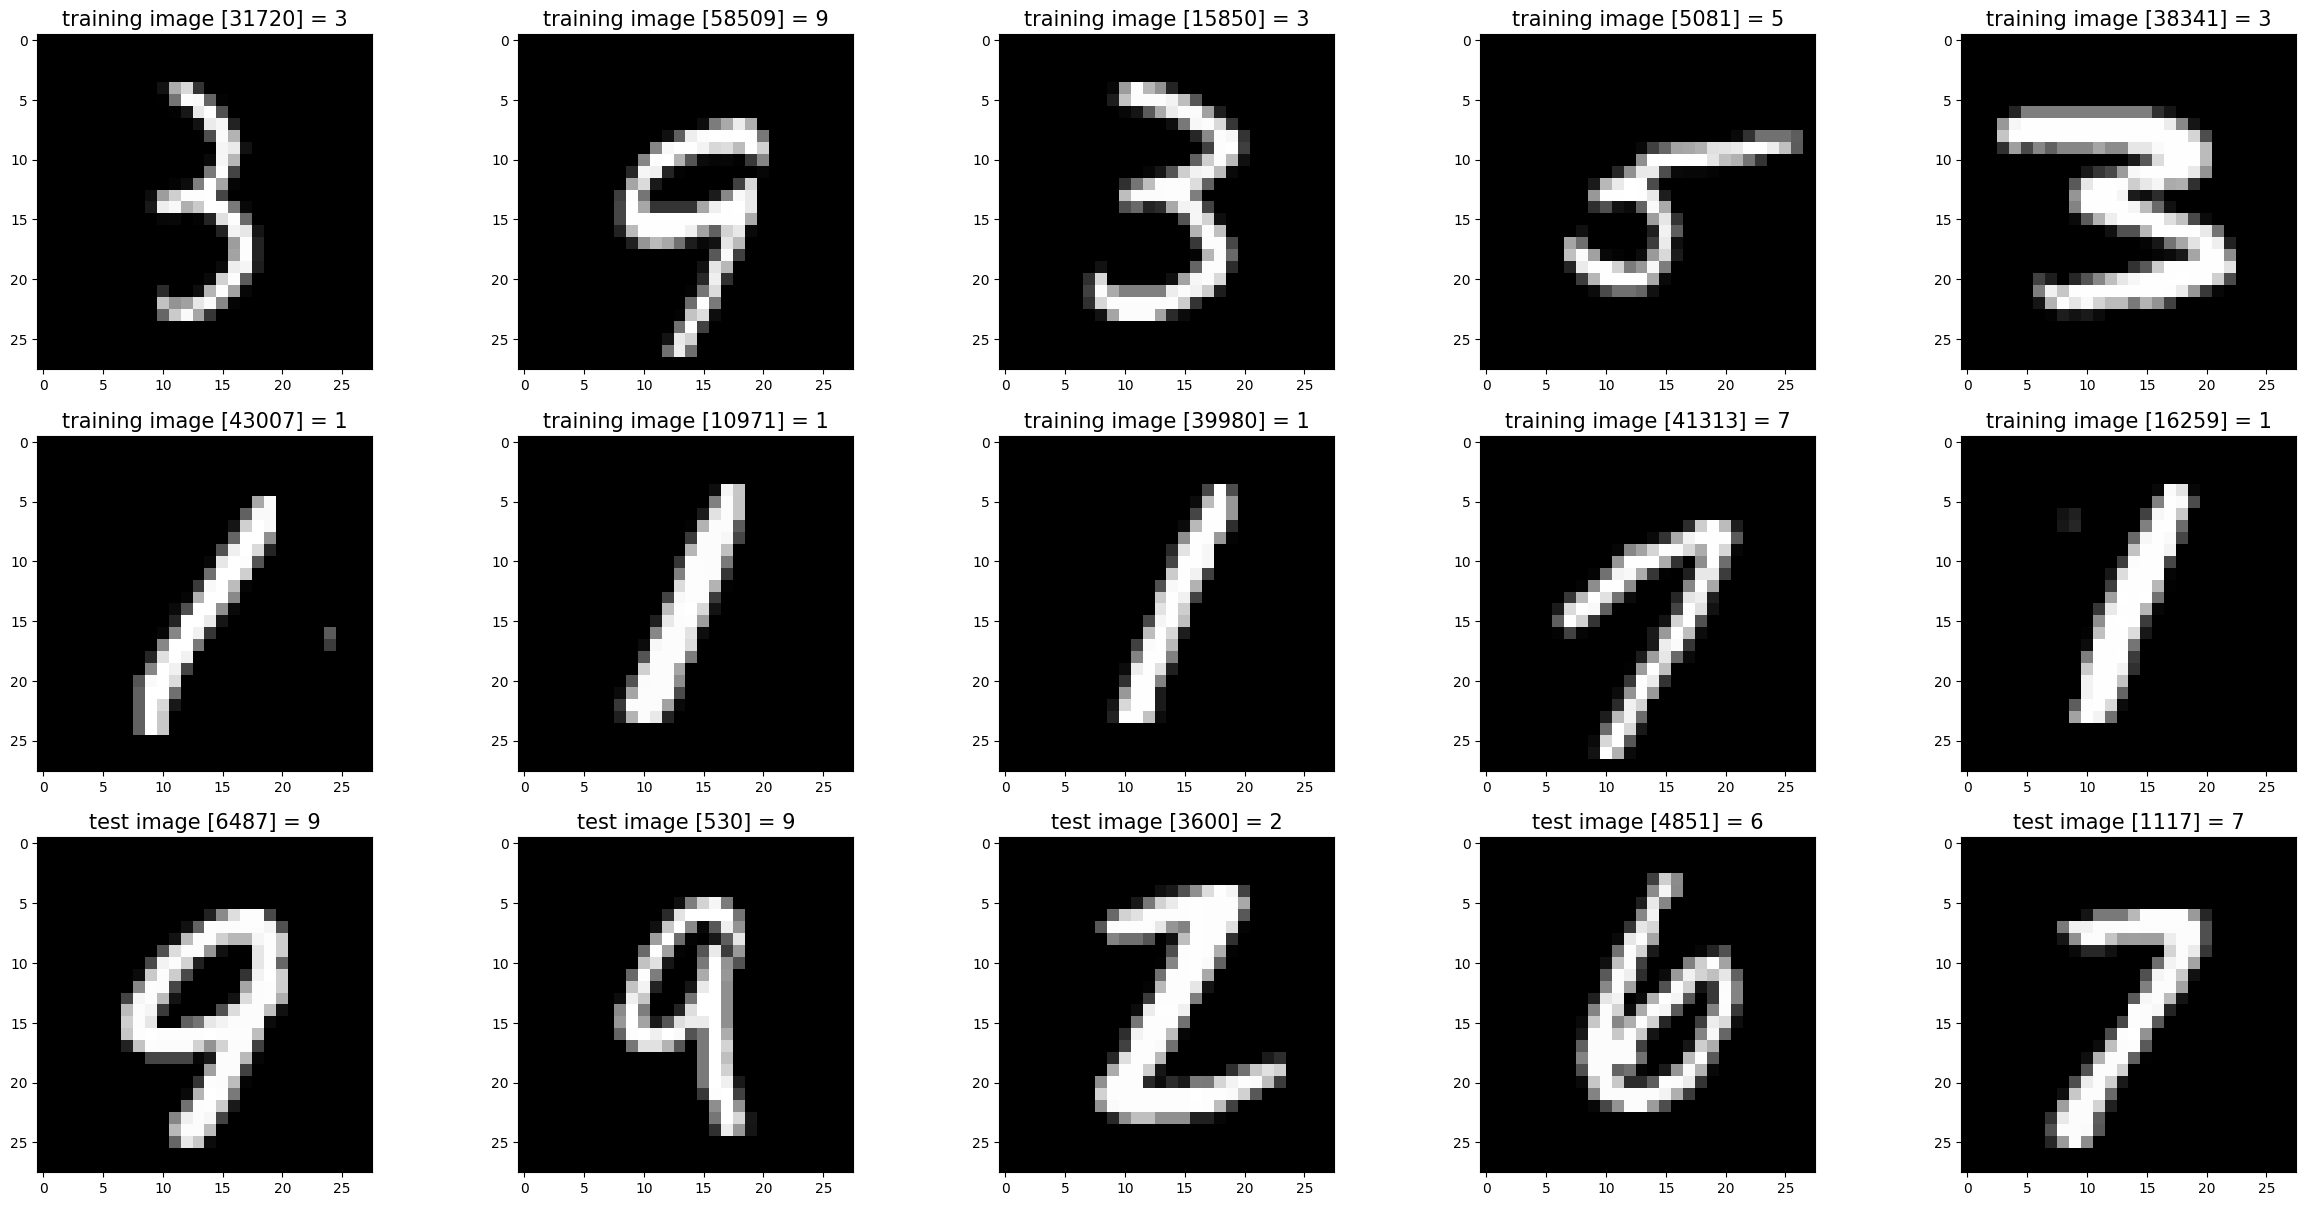

In [2]:
%matplotlib inline
import random
import matplotlib.pyplot as plt

input_path = 'archive/'
training_images_filepath = join(input_path, 'train-images-idx3-ubyte/train-images-idx3-ubyte')
training_labels_filepath = join(input_path, 'train-labels-idx1-ubyte/train-labels-idx1-ubyte')
test_images_filepath = join(input_path, 't10k-images-idx3-ubyte/t10k-images-idx3-ubyte')
test_labels_filepath = join(input_path, 't10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte')

def show_images(images, title_texts):
    cols = 5
    rows = int(len(images)/cols) + 1
    plt.figure(figsize=(30,20))
    index = 1    
    for x in zip(images, title_texts):        
        image = x[0]        
        title_text = x[1]
        plt.subplot(rows, cols, index)        
        plt.imshow(image, cmap=plt.cm.gray)
        if (title_text != ''):
            plt.title(title_text, fontsize = 15);        
        index += 1

mnist_dataloader = MnistDataloader(training_images_filepath, training_labels_filepath, test_images_filepath, test_labels_filepath)
(x_train, y_train), (x_test, y_test) = mnist_dataloader.load_data()

images_2_show = []
titles_2_show = []
for i in range(0, 10):
    r = random.randint(1, 60000)
    images_2_show.append(x_train[r])
    titles_2_show.append('training image [' + str(r) + '] = ' + str(y_train[r]))    

for i in range(0, 5):
    r = random.randint(1, 10000)
    images_2_show.append(x_test[r])        
    titles_2_show.append('test image [' + str(r) + '] = ' + str(y_test[r]))    

show_images(images_2_show, titles_2_show)

# Нормализуем данные

In [3]:
X_train = np.array(x_train, dtype=np.float32).reshape(-1, 784)
X_test  = np.array(x_test,  dtype=np.float32).reshape(-1, 784)
y_train = np.array(y_train, dtype=np.int64)
y_test  = np.array(y_test,  dtype=np.int64)

print(X_train.shape, X_train.dtype, X_train.min(), X_train.max())
print(y_train.shape, y_train[:10])

X_train = X_train / 255.0
X_test  = X_test  / 255.0

def one_hot(y, K=10):
    Y = np.zeros((len(y), K), dtype=np.float32)
    Y[np.arange(len(y)), y] = 1.0
    return Y

Y_train = one_hot(y_train)
Y_test  = one_hot(y_test)

(60000, 784) float32 0.0 255.0
(60000,) [5 0 4 1 9 2 1 3 1 4]


# Инициализация параметров
Для весов используем инициализацию He (Kaiming), а смещения проинициализиурем нулями

In [4]:
def init_params(D=784, s=128, K=10):
    W1 = np.random.normal(0.0, np.sqrt(2.0 / D), size=(s, D)).astype(np.float32)
    b1 = np.zeros(s, dtype=np.float32)
    W2 = np.random.normal(0.0, np.sqrt(2.0 / s), size=(K, s)).astype(np.float32)
    b2 = np.zeros(K, dtype=np.float32)
    return W1, b1, W2, b2

W1, b1, W2, b2 = init_params(s=128)
print(W1.shape, b1.shape, W2.shape, b2.shape)

(128, 784) (128,) (10, 128) (10,)


# Прямой ход

$z^{(1)} = W^{(1)}x + b^{(1)}$,
$h = ReLU(z^{1})$

$z^{(2)} = W^{(2)}h + b^{(2)}$, $\hat{y} = softmax(z^{(2)})$

$\hat{y}$ - вектор вероятности на выходе нейронной сети 

In [5]:
def relu(z):
    return np.maximum(0.0, z)

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def forward(X, W1, b1, W2, b2):
    Z1 = X @ W1.T + b1
    H  = relu(Z1)
    Z2 = H @ W2.T + b2
    Y_pred = softmax(Z2)
    cache = (X, Z1, H, Z2, Y_pred)
    return Y_pred, cache

# Обратный ход

Рассмотрим функцию потерь (кросс-энтропия)
$L = - \log\hat{y}_k = - z^{(2)}_k + \log\sum_j e^{z^{(2)}_j}$

$\delta^{(2)} = \hat{y} - y$

$\delta^{(1)} = W^{(2)T}\delta^{(2)}, z^{(1)} > 0$

$\nabla_{W^{(2)}}L = \delta^{(2)} h^T$,
$\nabla_{W^{(1)}}L = \delta^{(1)} x^T$

$\nabla_{b^{(2)}}L = \delta^{(2)}$,
$\nabla_{b^{(1)}}L = \delta^{(1)}$

In [6]:
def backward(cache, Y, W2):
    X, Z1, H, Z2, Y_pred = cache
    B = X.shape[0]

    dZ2 = (Y_pred - Y) / B

    dW2 = dZ2.T @ H
    db2 = dZ2.sum(axis=0)

    dH  = dZ2 @ W2
    dZ1 = dH * (Z1 > 0).astype(np.float32)
    dW1 = dZ1.T @ X
    db1 = dZ1.sum(axis=0)

    return dW1, db1, dW2, db2

# Обучение модели

In [7]:
def sgd_step(params, grads, lr):
    W1, b1, W2, b2 = params
    dW1, db1, dW2, db2 = grads
    W1 -= lr * dW1;  b1 -= lr * db1
    W2 -= lr * dW2;  b2 -= lr * db2
    return W1, b1, W2, b2

def train(X, Y, y, s=300, lr=0.1, batch_size=64, epochs=20):
    N, D = X.shape
    K = Y.shape[1]
    W1, b1, W2, b2 = init_params(D, s, K)

    for epoch in range(1, epochs + 1):
        start_time = time.time()

        idx = np.random.permutation(N)
        Xs, Ys, ys = X[idx], Y[idx], y[idx]

        correct_pred = 0

        for start in range(0, N, batch_size):
            end = min(start + batch_size, N)
            Xb, Yb, yb = Xs[start:end], Ys[start:end], ys[start:end]

            y_pred, cache = forward(Xb, W1, b1, W2, b2)
            
            grads = backward(cache, Yb, W2)
            W1, b1, W2, b2 = sgd_step((W1, b1, W2, b2), grads, lr)

            predictions = np.argmax(y_pred, axis=1)
            correct_pred += np.sum(predictions == yb)


        epoch_time = time.time() - start_time

        train_accuracy = correct_pred / N
        train_classification_error = 1 - train_accuracy

        print(f"epoch {epoch:2d}/{epochs} | train loss {train_classification_error:.4f} | time {epoch_time:.2f}s")

    return (W1, b1, W2, b2)

In [8]:
params = train(X_train, Y_train, y_train,
               s=128, lr=0.1, batch_size=64, epochs=20)

epoch  1/20 | train loss 0.1042 | time 0.64s
epoch  2/20 | train loss 0.0569 | time 0.71s
epoch  3/20 | train loss 0.0419 | time 0.66s
epoch  4/20 | train loss 0.0333 | time 1.01s
epoch  5/20 | train loss 0.0279 | time 0.55s
epoch  6/20 | train loss 0.0242 | time 0.59s
epoch  7/20 | train loss 0.0210 | time 0.57s
epoch  8/20 | train loss 0.0185 | time 0.59s
epoch  9/20 | train loss 0.0166 | time 0.62s
epoch 10/20 | train loss 0.0152 | time 0.60s
epoch 11/20 | train loss 0.0135 | time 0.59s
epoch 12/20 | train loss 0.0121 | time 0.56s
epoch 13/20 | train loss 0.0110 | time 0.57s
epoch 14/20 | train loss 0.0103 | time 0.60s
epoch 15/20 | train loss 0.0094 | time 0.59s
epoch 16/20 | train loss 0.0081 | time 0.75s
epoch 17/20 | train loss 0.0076 | time 0.60s
epoch 18/20 | train loss 0.0065 | time 0.55s
epoch 19/20 | train loss 0.0058 | time 0.56s
epoch 20/20 | train loss 0.0053 | time 0.56s


# Проверим работу на тестовой выборке
Вычислим accuracy

In [9]:
W1, b1, W2, b2 = params

y_pred, cache = forward(X_test, W1, b1, W2, b2)
predictions = np.argmax(y_pred, axis=1)
correct_pred = np.sum(predictions == y_test)

print(correct_pred / X_test.shape[0])

0.9793
